CUSTOMER SEGMENTATION DATASET


,Customer_ID,Age,Annual_Income,Spending_Score,Purchases_Per_Year
0,1,56,87,59,35
1,2,46,52,27,30
2,3,32,40,49,31
3,4,60,67,77,49
4,5,25,147,33,5
5,6,38,147,98,44
6,7,56,52,99,14
7,8,36,134,1,11
8,9,40,138,21,9
9,10,28,41,55,34



Dataset Shape:
(300, 5)

Missing Values:
Customer_ID           0
Age                   0
Annual_Income         0
Spending_Score        0
Purchases_Per_Year    0
dtype: int64

Statistical Summary:


,Customer_ID,Age,Annual_Income,Spending_Score,Purchases_Per_Year
count,300.000000,300.000000,300.000000,300.000000,300.000000
mean,150.500000,40.810000,85.093333,49.096667,25.176667
std,86.746758,13.547164,38.622579,30.058594,14.184597
min,1.000000,18.000000,20.000000,1.000000,1.000000
25%,75.750000,29.000000,51.750000,23.000000,12.000000
50%,150.500000,41.500000,82.000000,51.000000,26.000000
75%,225.250000,52.000000,119.000000,75.000000,37.000000
max,300.000000,64.000000,149.000000,100.000000,49.000000



Duplicate Records:
0


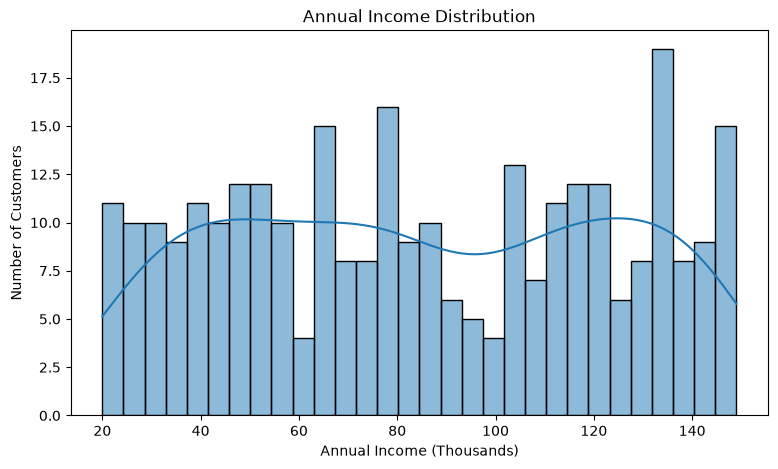

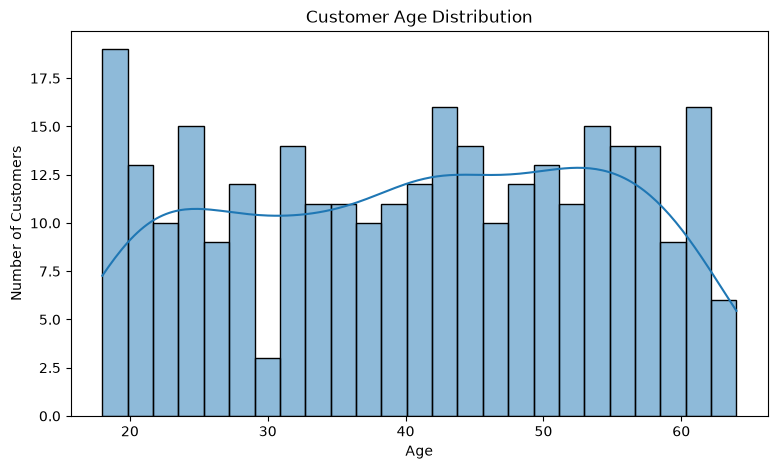

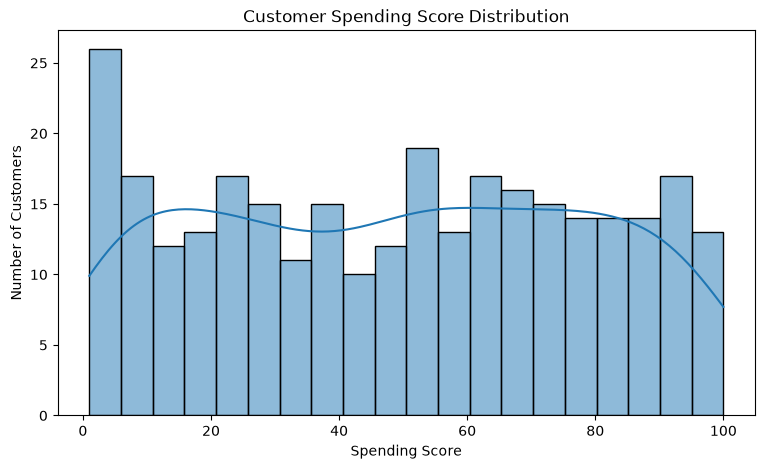

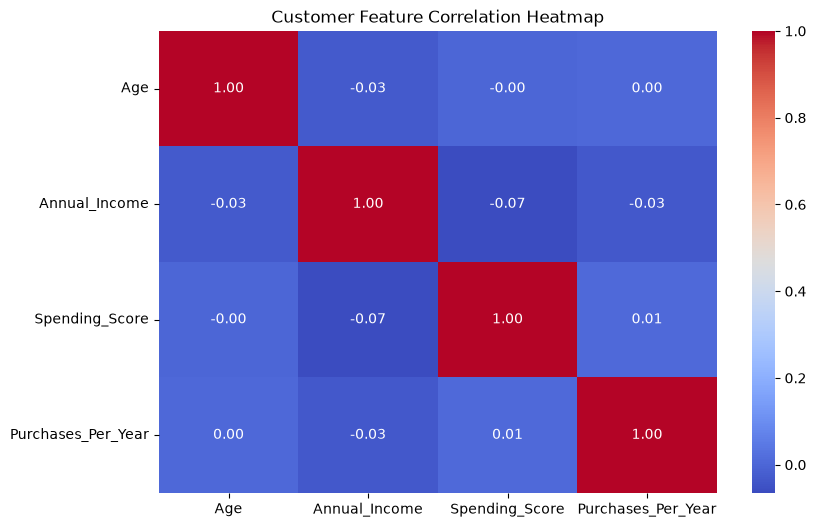


Data Standardization Completed.


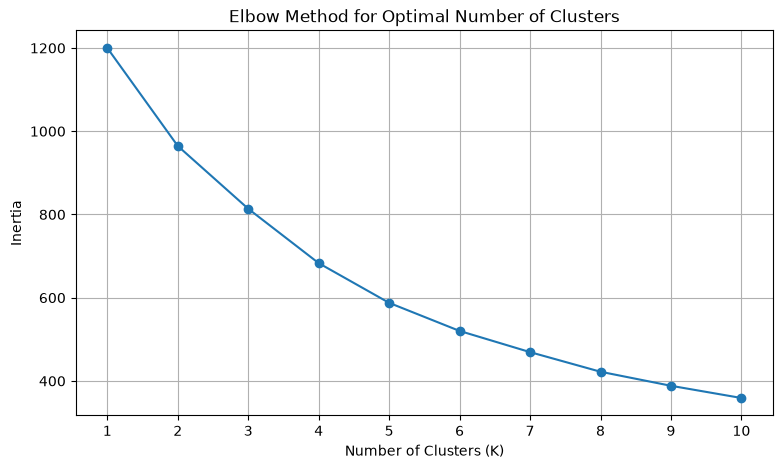


K-Means Clustering Completed.
Number of Clusters: 4

CUSTOMERS IN EACH CLUSTER
Cluster
0    80
1    87
2    70
3    63
Name: count, dtype: int64


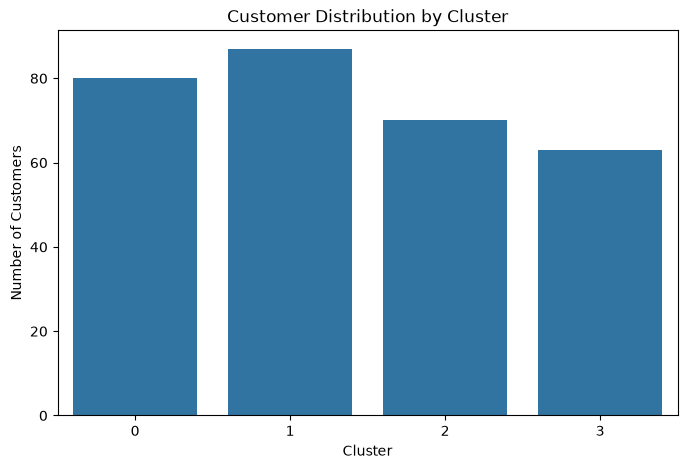

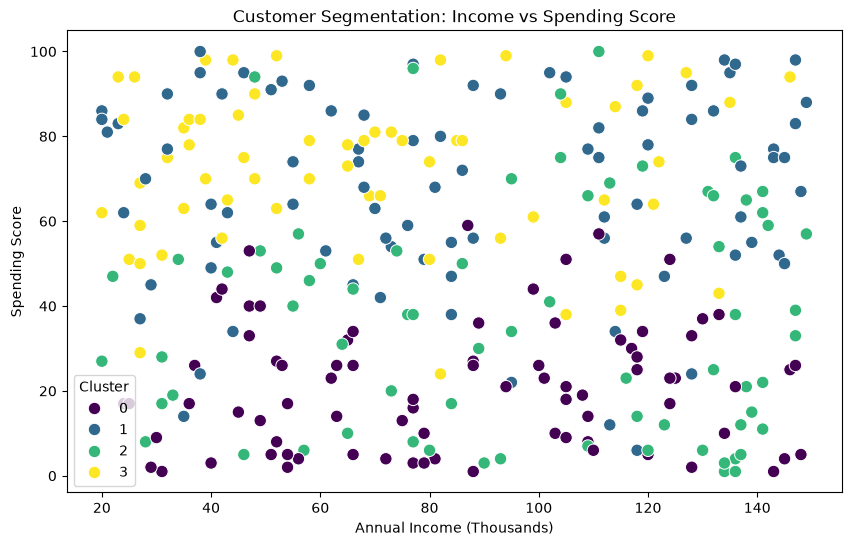

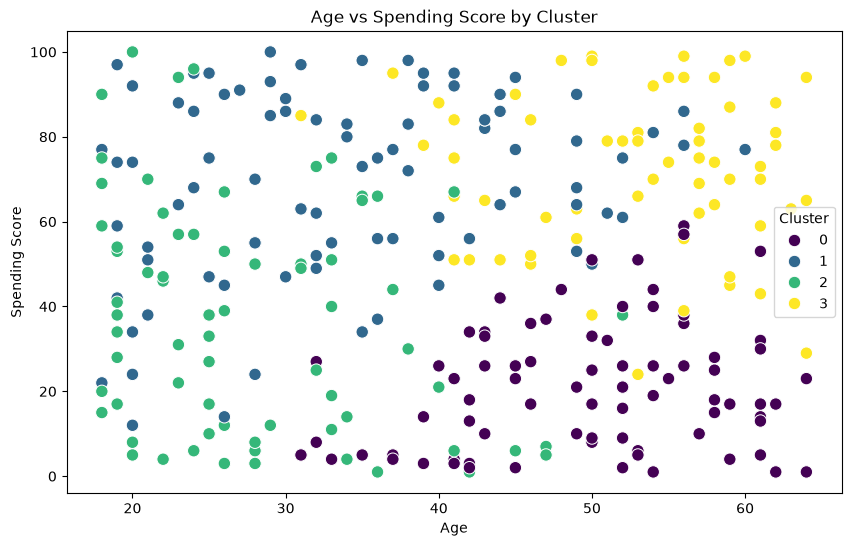

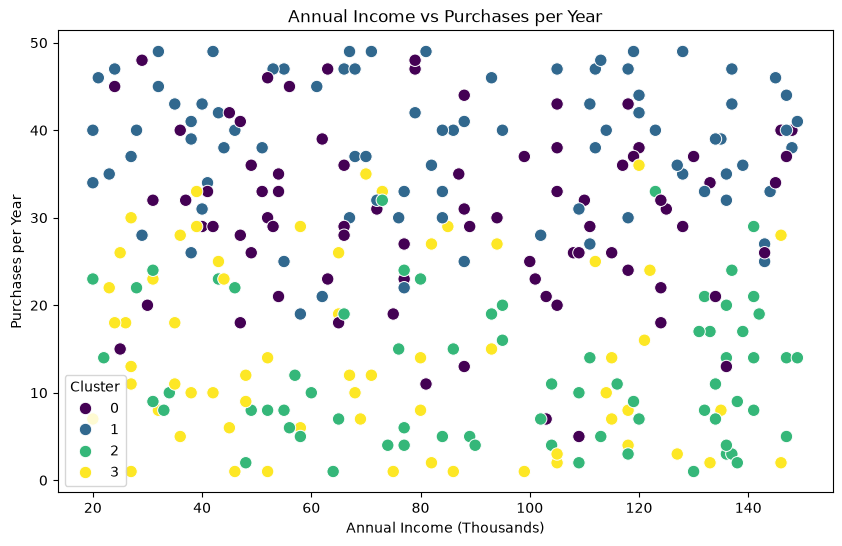

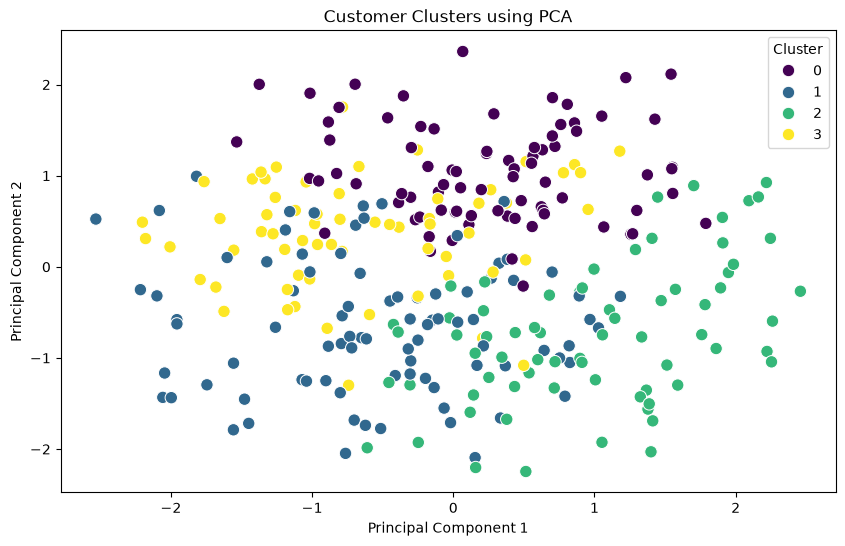


CLUSTER PROFILE


,Age,Annual_Income,Spending_Score,Purchases_Per_Year
Cluster,,,,
0,49.75,85.52,20.99,30.66
1,34.23,86.29,67.98,38.29
2,28.04,96.29,36.87,12.16
3,52.73,70.46,72.30,14.57


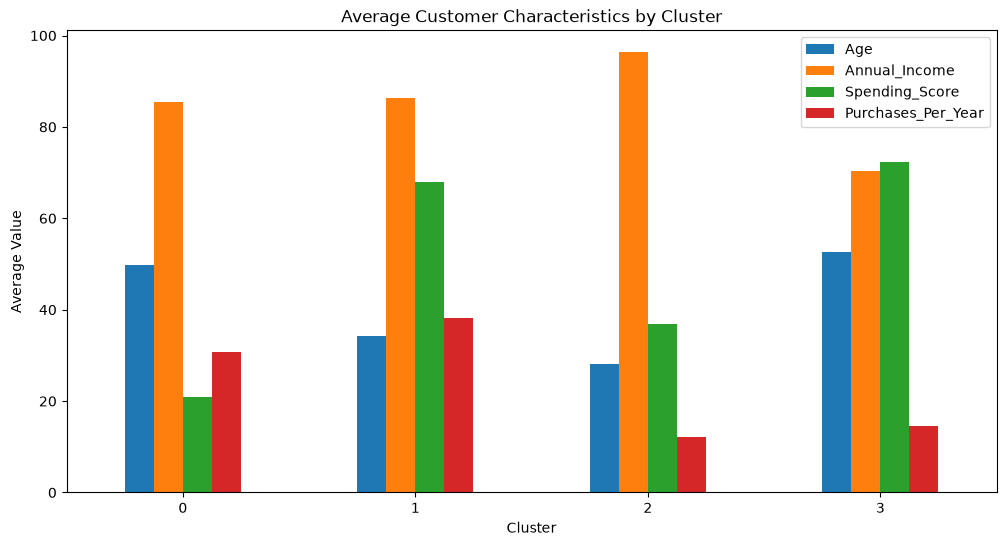


CUSTOMER SEGMENT ANALYSIS

Cluster 0
Average Age: 49.75
Average Income: 85.52 thousand
Average Spending Score: 20.99
Average Purchases per Year: 30.66

Cluster 1
Average Age: 34.23
Average Income: 86.29 thousand
Average Spending Score: 67.98
Average Purchases per Year: 38.29

Cluster 2
Average Age: 28.04
Average Income: 96.29 thousand
Average Spending Score: 36.87
Average Purchases per Year: 12.16

Cluster 3
Average Age: 52.73
Average Income: 70.46 thousand
Average Spending Score: 72.3
Average Purchases per Year: 14.57

Clustered dataset saved successfully as:
customer_segmentation_results.csv

PROJECT 1 COMPLETED SUCCESSFULLY!


In [1]:
# CUSTOMER SEGMENTATION USING K-MEANS CLUSTERING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

# ---------------------------------------------------------
# 1. CREATE CUSTOMER DATASET
# ---------------------------------------------------------

n = 300

df = pd.DataFrame({
    "Customer_ID": range(1, n + 1),
    "Age": np.random.randint(18, 65, n),
    "Annual_Income": np.random.randint(20, 150, n),
    "Spending_Score": np.random.randint(1, 101, n),
    "Purchases_Per_Year": np.random.randint(1, 50, n)
})

print("CUSTOMER SEGMENTATION DATASET")
print("=" * 50)

display(df.head(10))

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

# ---------------------------------------------------------
# 2. CHECK DUPLICATES
# ---------------------------------------------------------

print("\nDuplicate Records:")
print(df.duplicated().sum())

# ---------------------------------------------------------
# 3. BASIC DATA VISUALIZATION
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.histplot(
    df["Annual_Income"],
    bins=30,
    kde=True
)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income (Thousands)")
plt.ylabel("Number of Customers")
plt.show()

# ---------------------------------------------------------
# 4. AGE DISTRIBUTION
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.histplot(
    df["Age"],
    bins=25,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

# ---------------------------------------------------------
# 5. SPENDING SCORE DISTRIBUTION
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.histplot(
    df["Spending_Score"],
    bins=20,
    kde=True
)

plt.title("Customer Spending Score Distribution")
plt.xlabel("Spending Score")
plt.ylabel("Number of Customers")
plt.show()

# ---------------------------------------------------------
# 6. CORRELATION HEATMAP
# ---------------------------------------------------------

numeric_data = df[
    [
        "Age",
        "Annual_Income",
        "Spending_Score",
        "Purchases_Per_Year"
    ]
]

plt.figure(figsize=(9, 6))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Customer Feature Correlation Heatmap")
plt.show()

# ---------------------------------------------------------
# 7. SELECT FEATURES FOR CLUSTERING
# ---------------------------------------------------------

features = [
    "Age",
    "Annual_Income",
    "Spending_Score",
    "Purchases_Per_Year"
]

X = df[features]

# ---------------------------------------------------------
# 8. STANDARDIZE DATA
# ---------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nData Standardization Completed.")

# ---------------------------------------------------------
# 9. ELBOW METHOD
# ---------------------------------------------------------

inertia = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

# ---------------------------------------------------------
# 10. ELBOW CURVE
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, 11),
    inertia,
    marker="o"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid()

plt.show()

# ---------------------------------------------------------
# 11. APPLY K-MEANS
# ---------------------------------------------------------

optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

print("\nK-Means Clustering Completed.")
print("Number of Clusters:", optimal_k)

# ---------------------------------------------------------
# 12. CLUSTER COUNTS
# ---------------------------------------------------------

print("\nCUSTOMERS IN EACH CLUSTER")
print("=" * 40)

cluster_counts = df["Cluster"].value_counts().sort_index()

print(cluster_counts)

# ---------------------------------------------------------
# 13. CLUSTER DISTRIBUTION GRAPH
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.countplot(
    x="Cluster",
    data=df
)

plt.title("Customer Distribution by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()

# ---------------------------------------------------------
# 14. ANNUAL INCOME VS SPENDING SCORE
# ---------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="viridis",
    s=80
)

plt.title("Customer Segmentation: Income vs Spending Score")
plt.xlabel("Annual Income (Thousands)")
plt.ylabel("Spending Score")
plt.legend(title="Cluster")

plt.show()

# ---------------------------------------------------------
# 15. AGE VS SPENDING SCORE
# ---------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Spending_Score",
    hue="Cluster",
    palette="viridis",
    s=80
)

plt.title("Age vs Spending Score by Cluster")
plt.xlabel("Age")
plt.ylabel("Spending Score")

plt.show()

# ---------------------------------------------------------
# 16. PURCHASES VS INCOME
# ---------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Purchases_Per_Year",
    hue="Cluster",
    palette="viridis",
    s=80
)

plt.title("Annual Income vs Purchases per Year")
plt.xlabel("Annual Income (Thousands)")
plt.ylabel("Purchases per Year")

plt.show()

# ---------------------------------------------------------
# 17. PCA FOR 2D VISUALIZATION
# ---------------------------------------------------------

pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PCA1": X_pca[:, 0],
    "PCA2": X_pca[:, 1],
    "Cluster": df["Cluster"]
})

# ---------------------------------------------------------
# 18. PCA CLUSTER VISUALIZATION
# ---------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="viridis",
    s=80
)

plt.title("Customer Clusters using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

# ---------------------------------------------------------
# 19. CLUSTER PROFILE
# ---------------------------------------------------------

cluster_profile = df.groupby("Cluster")[
    [
        "Age",
        "Annual_Income",
        "Spending_Score",
        "Purchases_Per_Year"
    ]
].mean()

print("\nCLUSTER PROFILE")
print("=" * 60)

display(cluster_profile.round(2))

# ---------------------------------------------------------
# 20. CLUSTER PROFILE VISUALIZATION
# ---------------------------------------------------------

cluster_profile.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Customer Characteristics by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend()
plt.show()

# ---------------------------------------------------------
# 21. CUSTOMER SEGMENT ANALYSIS
# ---------------------------------------------------------

print("\nCUSTOMER SEGMENT ANALYSIS")
print("=" * 60)

for cluster in sorted(df["Cluster"].unique()):

    cluster_data = df[
        df["Cluster"] == cluster
    ]

    avg_age = cluster_data["Age"].mean()
    avg_income = cluster_data["Annual_Income"].mean()
    avg_spending = cluster_data["Spending_Score"].mean()
    avg_purchases = cluster_data["Purchases_Per_Year"].mean()

    print("\nCluster", cluster)

    print(
        "Average Age:",
        round(avg_age, 2)
    )

    print(
        "Average Income:",
        round(avg_income, 2),
        "thousand"
    )

    print(
        "Average Spending Score:",
        round(avg_spending, 2)
    )

    print(
        "Average Purchases per Year:",
        round(avg_purchases, 2)
    )

# ---------------------------------------------------------
# 22. SAVE CLUSTERED DATASET
# ---------------------------------------------------------

df.to_csv(
    "customer_segmentation_results.csv",
    index=False
)

print("\nClustered dataset saved successfully as:")
print("customer_segmentation_results.csv")

print("\nPROJECT 1 COMPLETED SUCCESSFULLY!")

NEWS ARTICLE DATASET


,Article_ID,Category,Article
0,1,Technology,Artificial intelligence is transforming the te...
1,2,Technology,Technology companies are developing advanced a...
2,3,Technology,Cloud computing and artificial intelligence ar...
3,4,Technology,New technology startups are using machine lear...
4,5,Technology,Cybersecurity experts are using artificial int...
5,6,Technology,The technology sector is investing heavily in ...
6,7,Technology,Machine learning algorithms are helping techno...
7,8,Technology,Cloud technology provides businesses with scal...
8,9,Technology,Artificial intelligence tools are becoming pop...
9,10,Technology,Technology researchers have developed a new ma...



Dataset Shape:
(50, 3)

Missing Values:
Article_ID    0
Category      0
Article       0
dtype: int64

Category Distribution:


Category
Technology    10
Sports        10
Business      10
Politics      10
Health        10
Name: count, dtype: int64

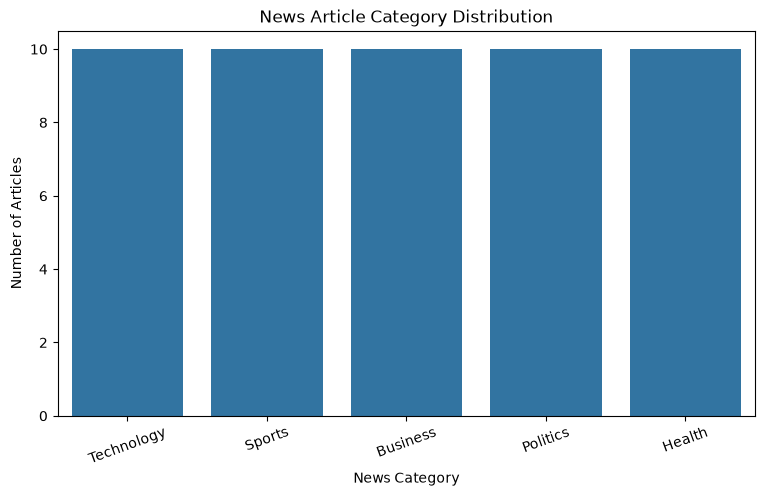

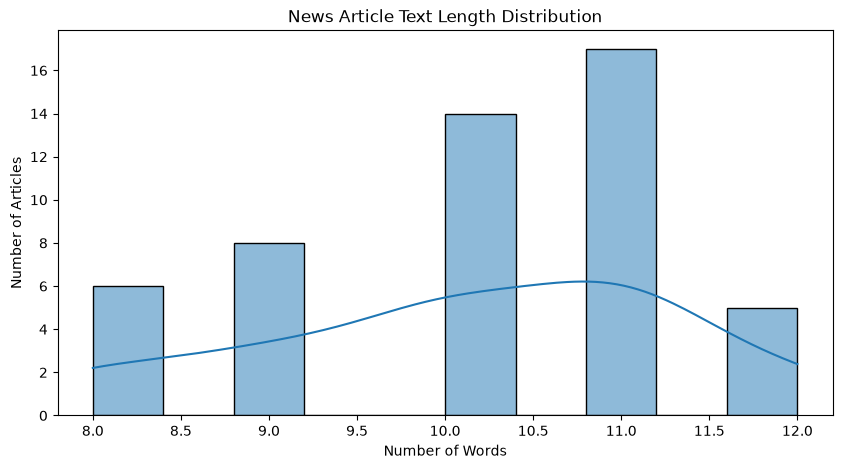


TF-IDF VECTORIZATION
Number of Articles: 50
Number of TF-IDF Features: 495


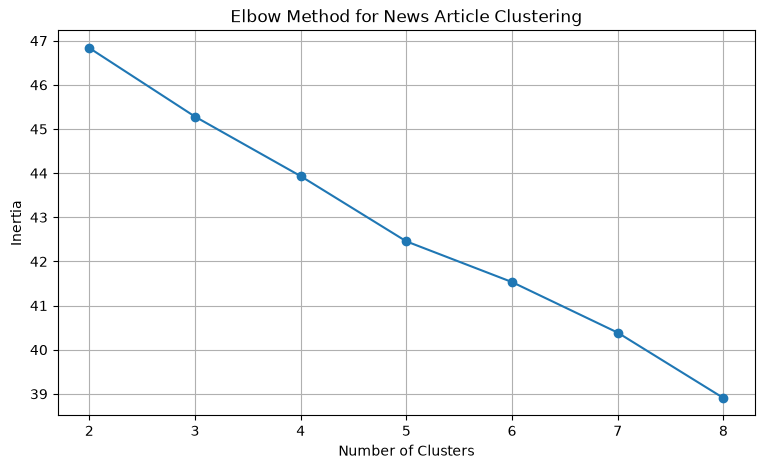

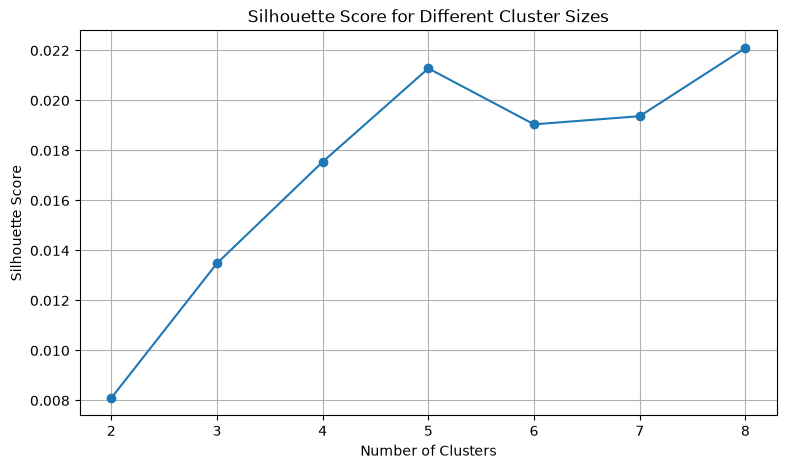


K-MEANS CLUSTERING COMPLETED
Number of Clusters: 5

Articles in Each Cluster:


Cluster
0    15
1    11
2    10
3     6
4     8
Name: count, dtype: int64

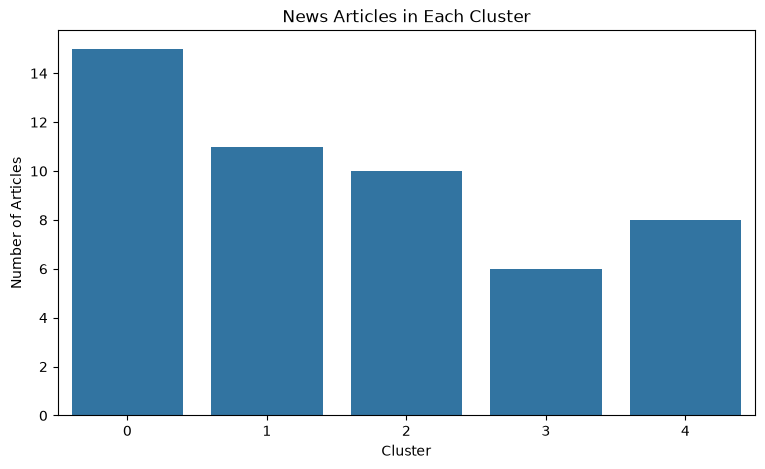

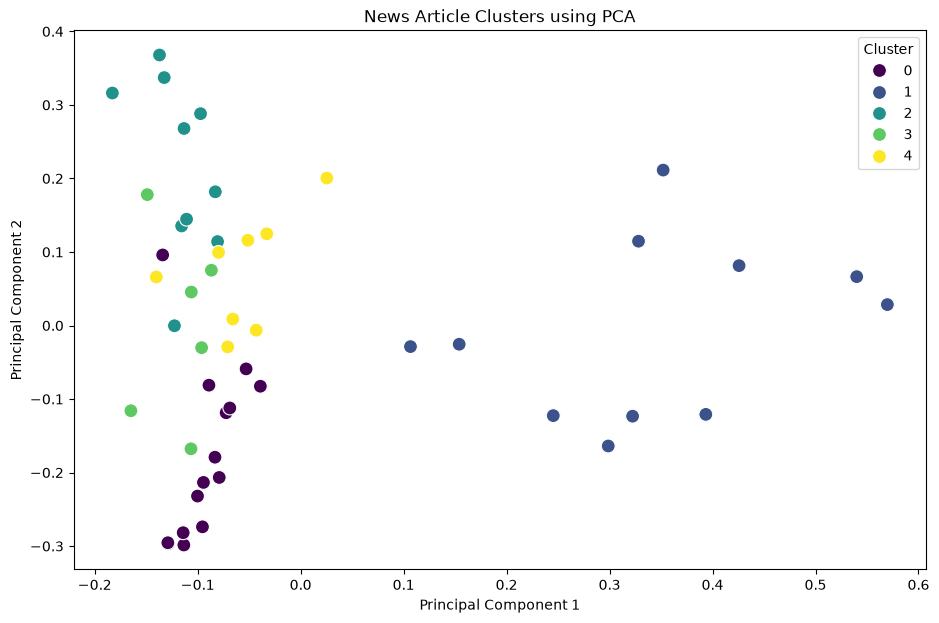


TOP WORDS IN EACH CLUSTER
Cluster 0 : players, upcoming, sports, cricket, election, football, team, championship, match, international
Cluster 1 : technology, intelligence, artificial, artificial intelligence, machine, machine learning, learning, software, using, advanced
Cluster 2 : business, financial, market, opportunities, new, growth, investors, new opportunities, investment, new investment
Cluster 3 : policy, government, development, national development, parliament, public, discussed, national, new, policy parliamentary
Cluster 4 : medical, diseases, treatment, improving, patient, new, treatments, doctors, improving patient, researchers

NEWS ARTICLES WITH CLUSTER ASSIGNMENTS


,Article_ID,Category,Article,Cluster
12,13,Sports,The sports team celebrated a major victory in ...,0
13,14,Sports,Football fans gathered to watch the important ...,0
15,16,Sports,Athletes are preparing for the national sports...,0
14,15,Sports,The cricket captain scored a century during th...,0
10,11,Sports,The football team won the championship after a...,0
11,12,Sports,Cricket players prepared for the upcoming inte...,0
17,18,Sports,Sports coaches are training players for the up...,0
16,17,Sports,The basketball team secured a place in the cha...,0
19,20,Sports,Cricket teams are practicing regularly before ...,0
18,19,Sports,The football club announced its new players fo...,0



CLUSTER VS ACTUAL CATEGORY


Category,Business,Health,Politics,Sports,Technology
Cluster,,,,,
0,0,2,3,10,0
1,0,1,0,0,10
2,10,0,0,0,0
3,0,0,6,0,0
4,0,7,1,0,0


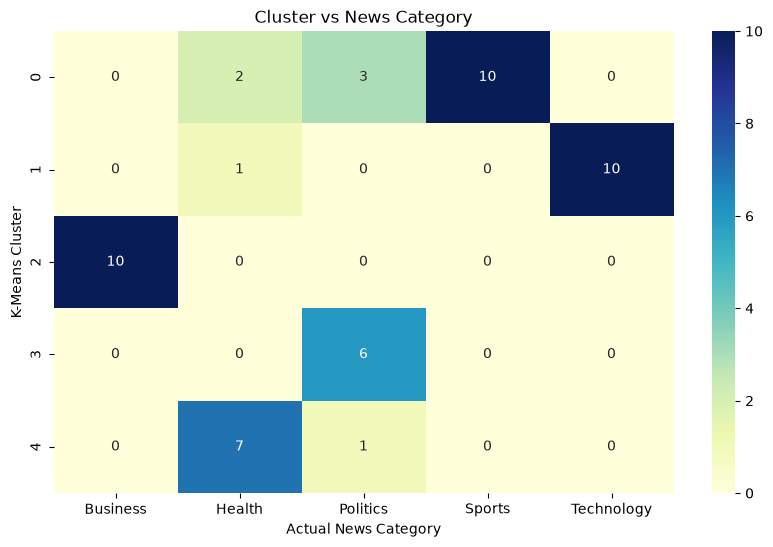


FINAL MODEL EVALUATION
Silhouette Score: 0.021
Inertia: 42.455

CLUSTER ANALYSIS

Cluster 0
--------------------------------------------------
Number of Articles: 15
Main Categories:
Category
Sports      10
Politics     3
Health       2
Name: count, dtype: int64
Important Words: players, upcoming, sports, cricket, election, football, team, championship, match, international

Cluster 1
--------------------------------------------------
Number of Articles: 11
Main Categories:
Category
Technology    10
Health         1
Name: count, dtype: int64
Important Words: technology, intelligence, artificial, artificial intelligence, machine, machine learning, learning, software, using, advanced

Cluster 2
--------------------------------------------------
Number of Articles: 10
Main Categories:
Category
Business    10
Name: count, dtype: int64
Important Words: business, financial, market, opportunities, new, growth, investors, new opportunities, investment, new investment

Cluster 3
--------------

In [2]:
# NEWS ARTICLE CLUSTERING SYSTEM
# TF-IDF + K-Means Clustering

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

# =========================================================
# 1. CREATE NEWS ARTICLE DATASET
# =========================================================

articles = [
    # Technology
    "Artificial intelligence is transforming the technology industry with new machine learning applications.",
    "Technology companies are developing advanced artificial intelligence and machine learning systems.",
    "Cloud computing and artificial intelligence are changing modern software development.",
    "New technology startups are using machine learning to develop innovative digital products.",
    "Cybersecurity experts are using artificial intelligence to detect online security threats.",
    "The technology sector is investing heavily in artificial intelligence research and development.",
    "Machine learning algorithms are helping technology companies improve their software products.",
    "Cloud technology provides businesses with scalable computing and data storage solutions.",
    "Artificial intelligence tools are becoming popular in software engineering and technology.",
    "Technology researchers have developed a new machine learning model for data analysis.",

    # Sports
    "The football team won the championship after an exciting final match.",
    "Cricket players prepared for the upcoming international tournament.",
    "The sports team celebrated a major victory in the championship competition.",
    "Football fans gathered to watch the important league match.",
    "The cricket captain scored a century during the international match.",
    "Athletes are preparing for the national sports competition.",
    "The basketball team secured a place in the championship final.",
    "Sports coaches are training players for the upcoming tournament.",
    "The football club announced its new players for the next season.",
    "Cricket teams are practicing regularly before the international series.",

    # Business
    "The company reported strong financial growth during the current business quarter.",
    "Business leaders discussed new investment opportunities in the global market.",
    "The stock market increased after companies announced positive financial results.",
    "Financial analysts expect business growth to continue during the next year.",
    "The company plans to expand its business operations into international markets.",
    "Investors are looking for new opportunities in the financial market.",
    "Business organizations are adopting new strategies to increase revenue.",
    "The financial sector experienced significant changes in the stock market.",
    "Corporate companies announced new investment and business expansion plans.",
    "Economic growth is creating new opportunities for businesses and investors.",

    # Politics
    "The government announced a new policy during the parliamentary session.",
    "Political leaders discussed national development and public policy.",
    "The parliament approved a new government policy after a long discussion.",
    "The election campaign focused on education, employment and economic development.",
    "Government officials announced plans for improving public services.",
    "Political parties are preparing for the upcoming national election.",
    "The minister discussed new policies for economic and social development.",
    "The government introduced legislation related to public welfare.",
    "Election candidates presented their plans to voters during the campaign.",
    "Parliament members debated the proposed national development policy.",

    # Health
    "Doctors are researching new treatments for diseases and improving patient care.",
    "Health experts recommend regular exercise and a balanced diet for healthy living.",
    "Medical researchers developed a new treatment for patients with chronic diseases.",
    "Hospitals are using advanced technology to improve healthcare services.",
    "Scientists are studying new medicines for the treatment of serious diseases.",
    "Healthcare workers are focusing on improving patient safety and medical services.",
    "Researchers are conducting clinical studies for new medical treatments.",
    "Doctors discussed the importance of preventive healthcare and regular checkups.",
    "The hospital introduced modern medical equipment for better patient treatment.",
    "Health organizations are promoting awareness about healthy lifestyles and disease prevention."
]

categories = (
    ["Technology"] * 10 +
    ["Sports"] * 10 +
    ["Business"] * 10 +
    ["Politics"] * 10 +
    ["Health"] * 10
)

df = pd.DataFrame({
    "Article_ID": range(1, 51),
    "Category": categories,
    "Article": articles
})

# =========================================================
# 2. DISPLAY DATASET
# =========================================================

print("NEWS ARTICLE DATASET")
print("=" * 60)

display(df.head(10))

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nCategory Distribution:")
display(df["Category"].value_counts())

# =========================================================
# 3. CATEGORY DISTRIBUTION VISUALIZATION
# =========================================================

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Category"
)

plt.title("News Article Category Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=20)

plt.show()

# =========================================================
# 4. TEXT LENGTH ANALYSIS
# =========================================================

df["Text_Length"] = df["Article"].apply(
    lambda x: len(x.split())
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Text_Length",
    bins=10,
    kde=True
)

plt.title("News Article Text Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")

plt.show()

# =========================================================
# 5. TF-IDF VECTORIZATION
# =========================================================

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=500,
    ngram_range=(1, 2)
)

X = vectorizer.fit_transform(df["Article"])

print("\nTF-IDF VECTORIZATION")
print("=" * 60)

print("Number of Articles:", X.shape[0])
print("Number of TF-IDF Features:", X.shape[1])

# =========================================================
# 6. FIND OPTIMAL NUMBER OF CLUSTERS
# =========================================================

inertia = []
silhouette_scores = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    inertia.append(model.inertia_)

    score = silhouette_score(
        X,
        labels
    )

    silhouette_scores.append(score)

# =========================================================
# 7. ELBOW METHOD VISUALIZATION
# =========================================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 9),
    inertia,
    marker="o"
)

plt.title("Elbow Method for News Article Clustering")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(2, 9))
plt.grid()

plt.show()

# =========================================================
# 8. SILHOUETTE SCORE VISUALIZATION
# =========================================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 9),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different Cluster Sizes")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid()

plt.show()

# =========================================================
# 9. APPLY K-MEANS CLUSTERING
# =========================================================

optimal_k = 5

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X)

print("\nK-MEANS CLUSTERING COMPLETED")
print("=" * 60)

print("Number of Clusters:", optimal_k)

# =========================================================
# 10. CLUSTER DISTRIBUTION
# =========================================================

cluster_counts = df["Cluster"].value_counts().sort_index()

print("\nArticles in Each Cluster:")
display(cluster_counts)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Cluster"
)

plt.title("News Articles in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Articles")

plt.show()

# =========================================================
# 11. PCA DIMENSIONALITY REDUCTION
# =========================================================

pca = PCA(
    n_components=2,
    random_state=42
)

X_dense = X.toarray()

X_pca = pca.fit_transform(X_dense)

df["PCA1"] = X_pca[:, 0]
df["PCA2"] = X_pca[:, 1]

# =========================================================
# 12. PCA CLUSTER VISUALIZATION
# =========================================================

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.title("News Article Clusters using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")

plt.show()

# =========================================================
# 13. TOP WORDS IN EACH CLUSTER
# =========================================================

terms = vectorizer.get_feature_names_out()

order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]

print("\nTOP WORDS IN EACH CLUSTER")
print("=" * 70)

cluster_keywords = {}

for i in range(optimal_k):

    top_words = [
        terms[ind]
        for ind in order_centroids[i, :10]
    ]

    cluster_keywords[i] = top_words

    print(
        "Cluster",
        i,
        ":",
        ", ".join(top_words)
    )

# =========================================================
# 14. DISPLAY ARTICLES WITH CLUSTERS
# =========================================================

print("\nNEWS ARTICLES WITH CLUSTER ASSIGNMENTS")
print("=" * 70)

display(
    df[
        [
            "Article_ID",
            "Category",
            "Article",
            "Cluster"
        ]
    ].sort_values("Cluster")
)

# =========================================================
# 15. COMPARE ACTUAL CATEGORY WITH CLUSTERS
# =========================================================

cluster_category_table = pd.crosstab(
    df["Cluster"],
    df["Category"]
)

print("\nCLUSTER VS ACTUAL CATEGORY")
print("=" * 70)

display(cluster_category_table)

# =========================================================
# 16. CLUSTER CATEGORY HEATMAP
# =========================================================

plt.figure(figsize=(10, 6))

sns.heatmap(
    cluster_category_table,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Cluster vs News Category")
plt.xlabel("Actual News Category")
plt.ylabel("K-Means Cluster")

plt.show()

# =========================================================
# 17. SILHOUETTE SCORE OF FINAL MODEL
# =========================================================

final_silhouette = silhouette_score(
    X,
    df["Cluster"]
)

print("\nFINAL MODEL EVALUATION")
print("=" * 60)

print(
    "Silhouette Score:",
    round(final_silhouette, 3)
)

print(
    "Inertia:",
    round(kmeans.inertia_, 3)
)

# =========================================================
# 18. CLUSTER ANALYSIS
# =========================================================

print("\nCLUSTER ANALYSIS")
print("=" * 70)

for cluster in sorted(df["Cluster"].unique()):

    cluster_articles = df[
        df["Cluster"] == cluster
    ]

    print("\nCluster", cluster)
    print("-" * 50)

    print(
        "Number of Articles:",
        len(cluster_articles)
    )

    print(
        "Main Categories:"
    )

    print(
        cluster_articles["Category"]
        .value_counts()
        .head(3)
    )

    print(
        "Important Words:",
        ", ".join(cluster_keywords[cluster])
    )

# =========================================================
# 19. PREDICT CLUSTER FOR A NEW NEWS ARTICLE
# =========================================================

new_article = [
    "Scientists developed new artificial intelligence technology for healthcare."
]

new_article_tfidf = vectorizer.transform(
    new_article
)

new_cluster = kmeans.predict(
    new_article_tfidf
)

print("\nNEW ARTICLE CLUSTER PREDICTION")
print("=" * 60)

print("Article:")
print(new_article[0])

print("\nPredicted Cluster:")
print(new_cluster[0])

print(
    "\nImportant Words in Predicted Cluster:"
)

print(
    ", ".join(
        cluster_keywords[new_cluster[0]]
    )
)

# =========================================================
# 20. SAVE RESULTS
# =========================================================

df.to_csv(
    "news_article_clustering_results.csv",
    index=False
)

print("\nResults saved successfully as:")
print("news_article_clustering_results.csv")

print("\nPROJECT 2 COMPLETED SUCCESSFULLY!")